# Install Libraries

conda install pandas numpy scipy scikit-learn matplotlib seaborn

# Import Libraries

In [8]:
import os
import zipfile
import urllib.request
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from scipy.sparse import csr_matrix
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")

sns.set_style("whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


# Download and Extract Dataset

In [7]:
project_folder = Path("Movie_Recommendation_System")
project_folder.mkdir(exist_ok=True)

dataset_url = "https://files.grouplens.org/datasets/movielens/ml-latest-small.zip"

zip_path = project_folder / "ml-latest-small.zip"
extract_path = project_folder / "ml-latest-small"

if not extract_path.exists():

    print("Downloading MovieLens dataset...")

    urllib.request.urlretrieve(dataset_url, zip_path)

    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(project_folder)

    print("Dataset downloaded and extracted successfully!")

else:
    print("Dataset already exists!")

Dataset downloaded and extracted successfully!


# Load CSV Files

In [9]:
ratings = pd.read_csv(extract_path / "ratings.csv")
movies = pd.read_csv(extract_path / "movies.csv")

print("Ratings Dataset:")
display(ratings.head())

print("\nMovies Dataset:")
display(movies.head())

Ratings Dataset:


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931



Movies Dataset:


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


# Explore Dataset

In [10]:
print("Ratings Dataset Shape:", ratings.shape)
print("Movies Dataset Shape:", movies.shape)

print("\nNumber of Users:", ratings["userId"].nunique())
print("Number of Rated Movies:", ratings["movieId"].nunique())

print("\nRatings Dataset Description:")
display(ratings.describe())

print("\nRatings Dataset Information:")
ratings.info()

print("\nMovies Dataset Information:")
movies.info()

Ratings Dataset Shape: (100836, 4)
Movies Dataset Shape: (9742, 3)

Number of Users: 610
Number of Rated Movies: 9724

Ratings Dataset Description:


,userId,movieId,rating,timestamp
count,100836.000000,100836.000000,100836.000000,1.008360e+05
mean,326.127564,19435.295718,3.501557,1.205946e+09
std,182.618491,35530.987199,1.042529,2.162610e+08
min,1.000000,1.000000,0.500000,8.281246e+08
25%,177.000000,1199.000000,3.000000,1.019124e+09
50%,325.000000,2991.000000,3.500000,1.186087e+09
75%,477.000000,8122.000000,4.000000,1.435994e+09
max,610.000000,193609.000000,5.000000,1.537799e+09



Ratings Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100836 entries, 0 to 100835
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   userId     100836 non-null  int64  
 1   movieId    100836 non-null  int64  
 2   rating     100836 non-null  float64
 3   timestamp  100836 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 3.1 MB

Movies Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9742 entries, 0 to 9741
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   movieId  9742 non-null   int64 
 1   title    9742 non-null   object
 2   genres   9742 non-null   object
dtypes: int64(1), object(2)
memory usage: 228.5+ KB


# Check Missing Values and Duplicates

In [12]:
print("Missing Values in Ratings:")
display(ratings.isnull().sum())

print("\nMissing Values in Movies:")
display(movies.isnull().sum())

print("\nDuplicate Ratings:", ratings.duplicated().sum())
print("Duplicate Movies:", movies.duplicated().sum())

Missing Values in Ratings:


userId       0
movieId      0
rating       0
timestamp    0
dtype: int64


Missing Values in Movies:


movieId    0
title      0
genres     0
dtype: int64


Duplicate Ratings: 0
Duplicate Movies: 0


# Clean the Dataset

In [13]:
ratings.dropna(
    subset=["userId", "movieId", "rating"],
    inplace=True
)

movies.dropna(
    subset=["movieId", "title"],
    inplace=True
)

ratings.drop_duplicates(
    subset=["userId", "movieId"],
    inplace=True
)

ratings["timestamp"] = pd.to_datetime(
    ratings["timestamp"],
    unit="s"
)

ratings = ratings[
    ratings["rating"].between(0.5, 5.0)
].copy()

print("Data preprocessing completed successfully!")

print("Cleaned Ratings Shape:", ratings.shape)

display(ratings.head())

Data preprocessing completed successfully!
Cleaned Ratings Shape: (100836, 4)


,userId,movieId,rating,timestamp
0,1,1,4.0,2000-07-30 18:45:03
1,1,3,4.0,2000-07-30 18:20:47
2,1,6,4.0,2000-07-30 18:37:04
3,1,47,5.0,2000-07-30 19:03:35
4,1,50,5.0,2000-07-30 18:48:51


# Create Rating Categories

In [14]:
def categorize_rating(rating):

    if rating <= 2.0:
        return "Low"

    elif rating <= 3.5:
        return "Medium"

    else:
        return "High"


ratings["rating_category"] = ratings["rating"].apply(
    categorize_rating
)

display(
    ratings[
        ["userId", "movieId", "rating", "rating_category"]
    ].head()
)

,userId,movieId,rating,rating_category
0,1,1,4.0,High
1,1,3,4.0,High
2,1,6,4.0,High
3,1,47,5.0,High
4,1,50,5.0,High


# Distribution of Movie Ratings

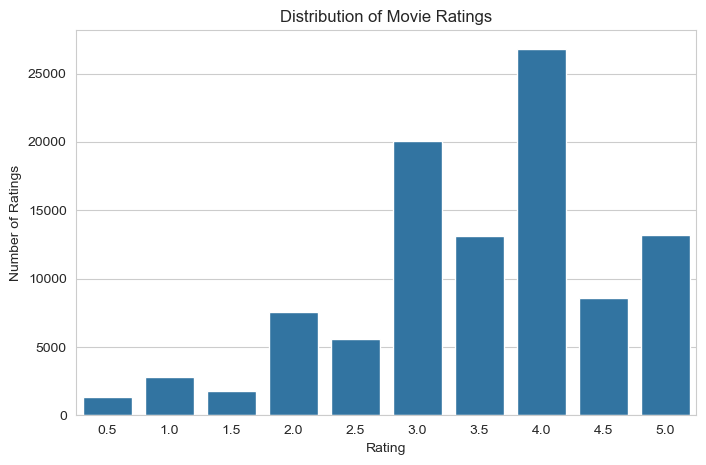

In [15]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=ratings,
    x="rating"
)

plt.title("Distribution of Movie Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")

plt.show()

# Movie Genre Analysis

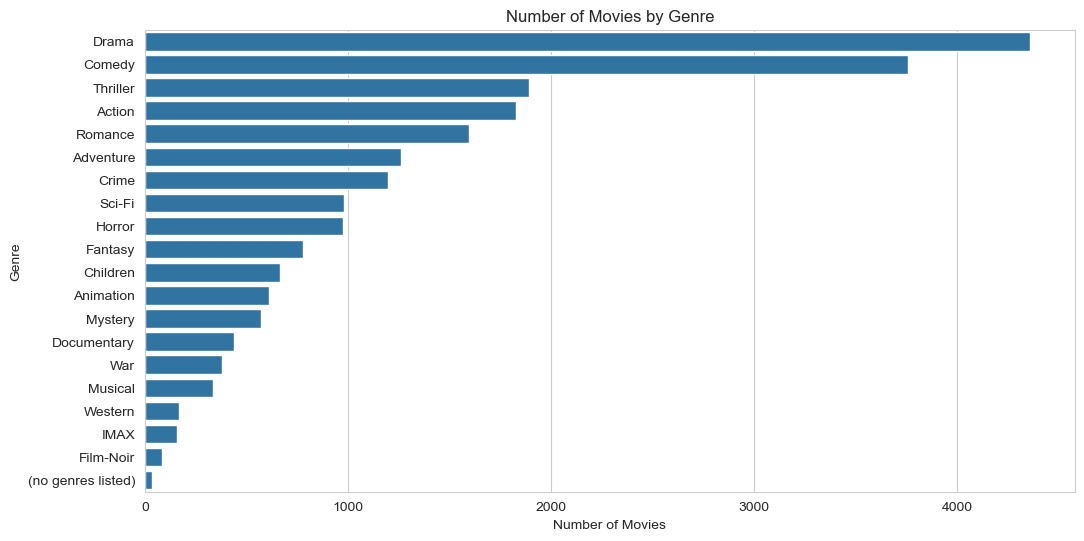

In [16]:
genre_data = movies.copy()

genre_data["genres"] = genre_data["genres"].str.split("|")

genre_data = genre_data.explode("genres")

genre_counts = genre_data["genres"].value_counts()

plt.figure(figsize=(12, 6))

sns.barplot(
    x=genre_counts.values,
    y=genre_counts.index
)

plt.title("Number of Movies by Genre")
plt.xlabel("Number of Movies")
plt.ylabel("Genre")

plt.show()

# User Activity Analysis

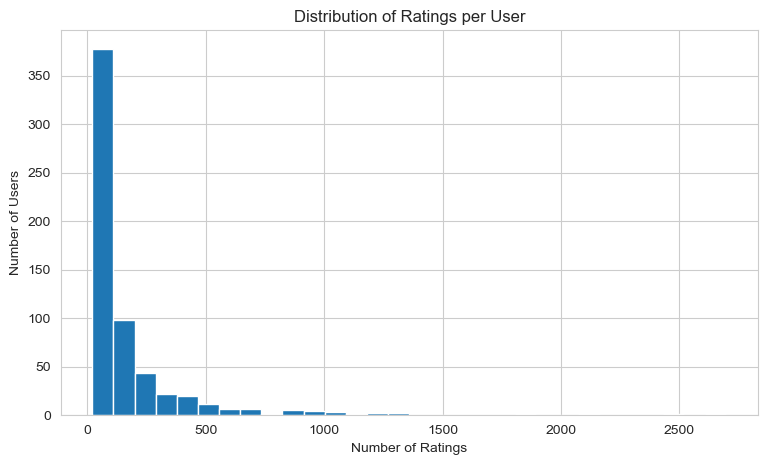

In [17]:
user_activity = ratings["userId"].value_counts()

plt.figure(figsize=(9, 5))

plt.hist(
    user_activity,
    bins=30
)

plt.title("Distribution of Ratings per User")
plt.xlabel("Number of Ratings")
plt.ylabel("Number of Users")

plt.show()

# Train-Test Split

In [18]:
train, test = train_test_split(
    ratings,
    test_size=0.2,
    random_state=42
)
print("Training Data Shape:", train.shape)
print("Testing Data Shape:", test.shape)
print("\nTraining Data:")
display(train.head())
print("\nTesting Data:")
display(test.head())

Training Data Shape: (80668, 5)
Testing Data Shape: (20168, 5)

Training Data:


,userId,movieId,rating,timestamp,rating_category
80568,509,7347,3.0,2015-07-04 07:23:17,Medium
50582,326,71462,4.0,2011-11-25 20:18:55,High
8344,57,2115,3.0,2000-08-09 05:15:55,Medium
99603,610,1127,4.0,2016-11-19 08:28:22,High
71701,462,2409,2.0,2007-03-21 00:50:49,Low



Testing Data:


,userId,movieId,rating,timestamp,rating_category
67037,432,77866,4.5,2012-04-23 00:07:21,High
42175,288,474,3.0,2001-01-02 19:59:25,Medium
93850,599,4351,3.0,2017-06-27 00:49:02,Medium
6187,42,2987,4.0,2001-07-27 19:37:57,High
12229,75,1610,4.0,2006-09-23 05:37:21,High


# Create Sparse Matrix

In [19]:
user_ids = sorted(ratings["userId"].unique())
movie_ids = sorted(ratings["movieId"].unique())
user_map = {
    user_id: index
    for index, user_id in enumerate(user_ids)
}
movie_map = {
    movie_id: index
    for index, movie_id in enumerate(movie_ids)
}
reverse_movie_map = {
    index: movie_id
    for movie_id, index in movie_map.items()
}
train_rows = train["movieId"].map(movie_map)
train_cols = train["userId"].map(user_map)
item_user_matrix = csr_matrix(
    (
        train["rating"].values,
        (train_rows.values, train_cols.values)
    ),
    shape=(len(movie_ids), len(user_ids))
)
print("User-Movie Matrix Created Successfully!")
print("Matrix Shape:", item_user_matrix.shape)
print("Number of Users:", len(user_ids))
print("Number of Movies:", len(movie_ids))
print("Number of Ratings:", item_user_matrix.nnz)
total_elements = (
    item_user_matrix.shape[0] *
    item_user_matrix.shape[1]
)
density = (
    item_user_matrix.nnz / total_elements
) * 100
print("Matrix Density:", round(density, 2), "%")

User-Movie Matrix Created Successfully!
Matrix Shape: (9724, 610)
Number of Users: 610
Number of Movies: 9724
Number of Ratings: 80668
Matrix Density: 1.36 %


# Train KNN Model

In [20]:
knn_model = NearestNeighbors(
    metric="cosine",
    algorithm="brute",
    n_neighbors=21
)

knn_model.fit(item_user_matrix)

print("KNN Model Trained Successfully!")

KNN Model Trained Successfully!


# Calculate Similarity

In [22]:
distances, indices = knn_model.kneighbors(
    item_user_matrix
)

similarities = 1 - distances

print("Cosine Similarity Calculated Successfully!")

print("Similarity Matrix Shape:", similarities.shape)

print("\nSample Similarity Values:")
print(similarities[0][:10])

Cosine Similarity Calculated Successfully!
Similarity Matrix Shape: (9724, 21)

Sample Similarity Values:
[1.         0.46949394 0.46279076 0.45961002 0.45822489 0.4565266
 0.45631403 0.45333311 0.45087716 0.45004616]


# Create Prediction Function

In [23]:
user_ratings = {}
for user_id, group in train.groupby("userId"):
    user_ratings[user_id] = dict(
        zip(group["movieId"], group["rating"])
    )
movie_mean_ratings = train.groupby(
    "movieId"
)["rating"].mean()
global_mean = train["rating"].mean()
def predict_rating(user_id, movie_id):
    if user_id not in user_map or movie_id not in movie_map:
        return float(global_mean)
    movie_index = movie_map[movie_id]
    neighbor_indices = indices[movie_index]
    neighbor_similarities = similarities[movie_index]
    numerator = 0
    denominator = 0
    rated_movies = user_ratings.get(user_id, {})
    for neighbor_index, similarity in zip(
        neighbor_indices,
        neighbor_similarities
    ):
        similar_movie_id = reverse_movie_map[neighbor_index]
        if similar_movie_id == movie_id:
            continue
        if (
            similar_movie_id in rated_movies
            and similarity > 0
        ):
            rating = rated_movies[similar_movie_id]
            numerator += similarity * rating
            denominator += abs(similarity)
    if denominator > 0:
        prediction = numerator / denominator
    else:
        prediction = movie_mean_ratings.get(
            movie_id,
            global_mean
        )
    prediction = np.clip(
        prediction,
        0.5,
        5.0
    )
    return float(prediction)
print("Rating Prediction Function Created Successfully!")

Rating Prediction Function Created Successfully!


# Test Prediction

In [24]:
sample_user = train.iloc[0]["userId"]
sample_movie = train.iloc[0]["movieId"]

predicted_rating = predict_rating(
    sample_user,
    sample_movie
)

print("User ID:", sample_user)
print("Movie ID:", sample_movie)
print("Predicted Rating:", round(predicted_rating, 2))

User ID: 509
Movie ID: 7347
Predicted Rating: 2.87


# Create Recommendation Function

In [26]:
def recommend_movies(user_id, top_n=10):
    if user_id not in user_map:
        print("User not found!")
        return pd.DataFrame()
    watched_movies = set(
        user_ratings.get(user_id, {}).keys()
    )
    candidate_movies = [
        movie_id
        for movie_id in movie_ids
        if movie_id not in watched_movies
    ]
    recommendations = []
    for movie_id in candidate_movies:
        predicted = predict_rating(
            user_id,
            movie_id
        )
        recommendations.append(
            (movie_id, predicted)
        )
    recommendations.sort(
        key=lambda x: x[1],
        reverse=True
    )
    top_recommendations = recommendations[:top_n]
    result = pd.DataFrame(
        top_recommendations,
        columns=["movieId", "Predicted Rating"]
    )
    result = result.merge(
        movies[["movieId", "title", "genres"]],
        on="movieId",
        how="left"
    )
    return result[
        ["movieId", "title", "genres", "Predicted Rating"]
    ]

# Generate Recommendations

In [27]:
most_active_user = train["userId"].value_counts().idxmax()

print("Selected User ID:", most_active_user)

recommendations = recommend_movies(
    most_active_user,
    top_n=10
)

print("\nTop 10 Movie Recommendations:")

display(recommendations)

Selected User ID: 414

Top 10 Movie Recommendations:


,movieId,title,genres,Predicted Rating
0,53,Lamerica (1994),Adventure|Drama,5.0
1,495,In the Realm of the Senses (Ai no corrida) (1976),Drama,5.0
2,1103,Rebel Without a Cause (1955),Drama,5.0
3,1208,Apocalypse Now (1979),Action|Drama|War,5.0
4,1310,Hype! (1996),Documentary,5.0
5,1349,Vampire in Venice (Nosferatu a Venezia) (Nosfe...,Horror,5.0
6,1759,"Four Days in September (O Que É Isso, Companhe...",Drama,5.0
7,2068,Fanny and Alexander (Fanny och Alexander) (1982),Drama|Fantasy|Mystery,5.0
8,3303,Black Tar Heroin: The Dark End of the Street (...,Documentary,5.0
9,3473,Jonah Who Will Be 25 in the Year 2000 (Jonas q...,Comedy,5.0


# Calculate MAE and RMSE

In [28]:
evaluation_sample = test.sample(
    n=min(5000, len(test)),
    random_state=42
)
actual_ratings = []
predicted_ratings = []
for _, row in evaluation_sample.iterrows():
    actual = row["rating"]
    predicted = predict_rating(
        row["userId"],
        row["movieId"]
    )
    actual_ratings.append(actual)
    predicted_ratings.append(predicted)
mae = mean_absolute_error(
    actual_ratings,
    predicted_ratings
)
rmse = np.sqrt(
    mean_squared_error(
        actual_ratings,
        predicted_ratings
    )
)
print("KNN MODEL EVALUATION")
print("--------------------")

print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))

KNN MODEL EVALUATION
--------------------
MAE: 0.7178
RMSE: 0.9515


# Popularity-Based Model

In [30]:
popularity_scores = train.groupby(
    "movieId"
)["rating"].mean()
popularity_predictions = []
for _, row in evaluation_sample.iterrows():
    movie_id = row["movieId"]
    predicted = popularity_scores.get(
        movie_id,
        global_mean
    )
    popularity_predictions.append(predicted)
popularity_mae = mean_absolute_error(
    evaluation_sample["rating"],
    popularity_predictions
)
popularity_rmse = np.sqrt(
    mean_squared_error(
        evaluation_sample["rating"],
        popularity_predictions
    )
)
comparison = pd.DataFrame({
    "Model": [
        "Popularity Based",
        "KNN Collaborative Filtering"
    ],
    "MAE": [
        popularity_mae,
        mae
    ],
    "RMSE": [
        popularity_rmse,
        rmse
    ]
})
print("MODEL PERFORMANCE COMPARISON")
display(comparison)

MODEL PERFORMANCE COMPARISON


,Model,MAE,RMSE
0,Popularity Based,0.780968,1.004178
1,KNN Collaborative Filtering,0.717778,0.951459


# Plot Comparison Graph

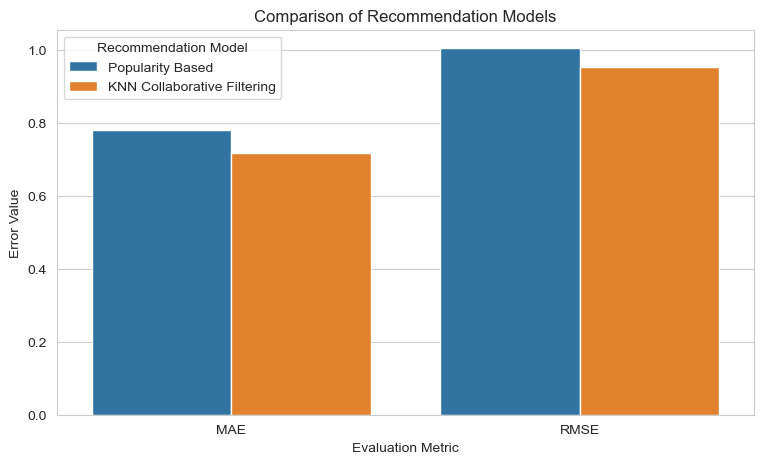

In [31]:
plt.figure(figsize=(9, 5))

comparison_melted = comparison.melt(
    id_vars="Model",
    value_vars=["MAE", "RMSE"],
    var_name="Metric",
    value_name="Error"
)

sns.barplot(
    data=comparison_melted,
    x="Metric",
    y="Error",
    hue="Model"
)

plt.title("Comparison of Recommendation Models")
plt.xlabel("Evaluation Metric")
plt.ylabel("Error Value")

plt.legend(title="Recommendation Model")

plt.show()

# Final Output

In [32]:
print("=" * 55)
print("       MOVIE RECOMMENDATION SYSTEM")
print("=" * 55)

print("\nDATASET INFORMATION")
print("-------------------")

print("Total Users:", ratings["userId"].nunique())
print("Total Movies:", ratings["movieId"].nunique())
print("Total Ratings:", len(ratings))

print("\nRECOMMENDATION MODEL")
print("--------------------")

print("Algorithm: Item-Based Collaborative Filtering")
print("Technique: K-Nearest Neighbors")
print("Similarity Measure: Cosine Similarity")

print("\nKNN MODEL EVALUATION")
print("--------------------")

print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))

print("\nPOPULARITY BASELINE")
print("-------------------")

print("MAE:", round(popularity_mae, 4))
print("RMSE:", round(popularity_rmse, 4))

print("\nProject Execution Completed Successfully!")

print("=" * 55)

       MOVIE RECOMMENDATION SYSTEM

DATASET INFORMATION
-------------------
Total Users: 610
Total Movies: 9724
Total Ratings: 100836

RECOMMENDATION MODEL
--------------------
Algorithm: Item-Based Collaborative Filtering
Technique: K-Nearest Neighbors
Similarity Measure: Cosine Similarity

KNN MODEL EVALUATION
--------------------
MAE: 0.7178
RMSE: 0.9515

POPULARITY BASELINE
-------------------
MAE: 0.781
RMSE: 1.0042

Project Execution Completed Successfully!
